# Analyse de performance par employé (ventes / clients / panier moyen)

## Objectif
Mesurer des indicateurs de performance par employé (chiffre d’affaires, nombre de clients gérés, nombre de commandes, panier moyen).

## Intérêt métier
- Identifier les employés à forte contribution au chiffre d’affaires
- Comparer efficacité commerciale (CA) vs portefeuille (clients gérés)
- Détecter des profils : "gros portefeuille / faible CA" ou "petit portefeuille / gros CA"

In [9]:
from pathlib import Path
import sys

# Trouver la racine du projet en remontant jusqu'à trouver requirements.txt + src + visualizations
PROJECT_ROOT = None
for p in Path().resolve().parents:
    if (p / "requirements.txt").exists() and (p / "src").exists() and (p / "visualizations").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Impossible de trouver PROJECT_ROOT. Ouvre le notebook depuis le repo du projet.")

# Ajouter le projet au PATH pour pouvoir importer src.*
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, OUTPUT_DIR


(WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis'),
 WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/visualizations/part4'))

## Justification (technique)
On calcule dynamiquement la racine du projet afin de rendre le notebook **portable** :
- l’exécution fonctionne même si le dossier courant n’est pas celui du projet,
- les imports `src.*` restent valides,
- les exports PNG sont sauvegardés systématiquement dans `visualizations/part4`.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from src.analysis.db import get_connection
def fetch_df(query, params=None):
    conn = get_connection()
    try:
        return pd.read_sql(query, conn, params=params)
    finally:
        conn.close()

# Test connexion (doit afficher un objet connexion puis se fermer)
conn = get_connection()
print(conn)
conn.close()

## Justification (extraction SQL)
On calcule des KPI **par employé** via jointures :
- `employees` : référentiel employé
- `customers` : portefeuille via `salesRepEmployeeNumber`
- `payments` : chiffre d’affaires encaissé
- `orders` + `orderdetails` : panier moyen et volume de commandes

Les requêtes sont structurées pour éviter les doublons et garder une logique lisible.

In [11]:
sql_revenue_clients = """
SELECT 
    e.employeeNumber,
    CONCAT(e.firstName, ' ', e.lastName) AS employeeName,
    e.jobTitle,
    COUNT(DISTINCT c.customerNumber) AS customers_managed,
    COALESCE(SUM(p.amount), 0) AS revenue
FROM employees e
LEFT JOIN customers c 
    ON c.salesRepEmployeeNumber = e.employeeNumber
LEFT JOIN payments p
    ON p.customerNumber = c.customerNumber
GROUP BY e.employeeNumber, employeeName, e.jobTitle
ORDER BY revenue DESC;
"""

df_emp = fetch_df(sql_revenue_clients)
df_emp.head()

C:\Users\canpe\AppData\Local\Temp\ipykernel_64368\771926566.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn, params=params)


,employeeNumber,employeeName,jobTitle,customers_managed,revenue
0,1370,Gerard Hernandez,Sales Rep,7,1112003.81
1,1165,Leslie Jennings,Sales Rep,6,989906.55
2,1401,Pamela Castillo,Sales Rep,10,750201.87
3,1501,Larry Bott,Sales Rep,8,686653.25
4,1504,Barry Jones,Sales Rep,9,637672.65


In [12]:
sql_orders_basket = """
WITH order_totals AS (
    SELECT
        o.orderNumber,
        o.customerNumber,
        SUM(od.quantityOrdered * od.priceEach) AS order_total
    FROM orders o
    JOIN orderdetails od ON od.orderNumber = o.orderNumber
    GROUP BY o.orderNumber, o.customerNumber
)
SELECT
    e.employeeNumber,
    CONCAT(e.firstName, ' ', e.lastName) AS employeeName,
    COUNT(DISTINCT ot.orderNumber) AS nb_orders,
    COALESCE(AVG(ot.order_total), 0) AS avg_basket
FROM employees e
LEFT JOIN customers c ON c.salesRepEmployeeNumber = e.employeeNumber
LEFT JOIN order_totals ot ON ot.customerNumber = c.customerNumber
GROUP BY e.employeeNumber, employeeName
ORDER BY nb_orders DESC;
"""

df_orders = fetch_df(sql_orders_basket)
df_orders.head()


C:\Users\canpe\AppData\Local\Temp\ipykernel_64368\771926566.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn, params=params)


,employeeNumber,employeeName,nb_orders,avg_basket
0,1370,Gerard Hernandez,43,29269.251395
1,1165,Leslie Jennings,34,31809.721765
2,1401,Pamela Castillo,31,28007.114516
3,1504,Barry Jones,25,28194.156400
4,1323,George Vanauf,22,30426.229545


In [13]:
df = df_emp.merge(df_orders, on=["employeeNumber", "employeeName"], how="left")
df["nb_orders"] = df["nb_orders"].fillna(0).astype(int)
df["avg_basket"] = df["avg_basket"].fillna(0.0)

df.sort_values("revenue", ascending=False).head(10)

,employeeNumber,employeeName,jobTitle,customers_managed,revenue,nb_orders,avg_basket
0,1370,Gerard Hernandez,Sales Rep,7,1112003.81,43,29269.251395
1,1165,Leslie Jennings,Sales Rep,6,989906.55,34,31809.721765
2,1401,Pamela Castillo,Sales Rep,10,750201.87,31,28007.114516
3,1501,Larry Bott,Sales Rep,8,686653.25,22,33277.126818
4,1504,Barry Jones,Sales Rep,9,637672.65,25,28194.156400
5,1323,George Vanauf,Sales Rep,8,584406.80,22,30426.229545
6,1337,Loui Bondur,Sales Rep,6,569485.75,20,28474.287500
7,1611,Andy Fixter,Sales Rep,5,509385.82,19,29609.610000
8,1612,Peter Marsh,Sales Rep,5,497907.16,19,30768.092632
9,1286,Foon Yue Tseng,Sales Rep,7,488212.67,17,28718.392353


## Justification (KPI)
- **Revenue** (payments) : mesure l’argent réellement encaissé, donc plus fiable qu’un simple total de commandes.
- **Customers managed** : taille du portefeuille commercial.
- **Nb orders** : activité commerciale / volume.
- **Avg basket** : panier moyen, utile pour comparer “qualité” des ventes (montant par commande).

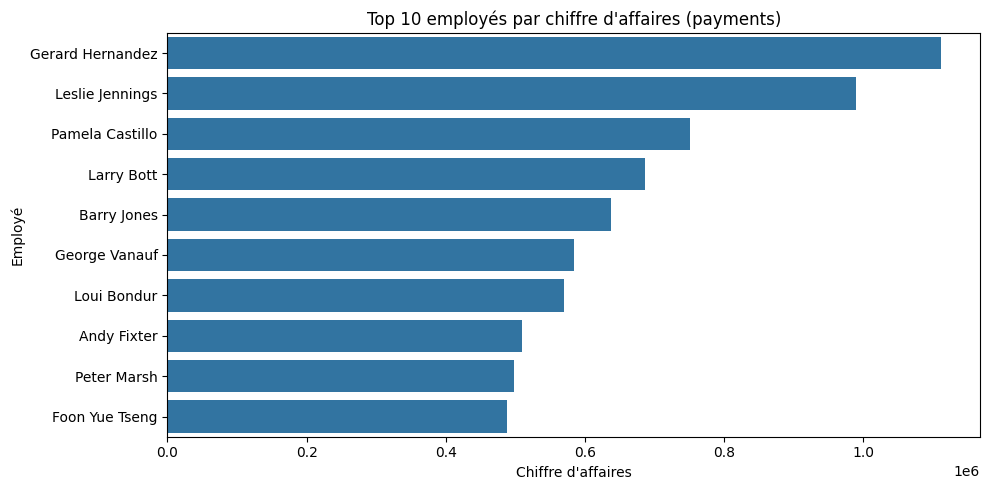

In [14]:
top_n = 10
df_top = df.sort_values("revenue", ascending=False).head(top_n)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_top, x="revenue", y="employeeName")
plt.title(f"Top {top_n} employés par chiffre d'affaires (payments)")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Employé")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_employee_top_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

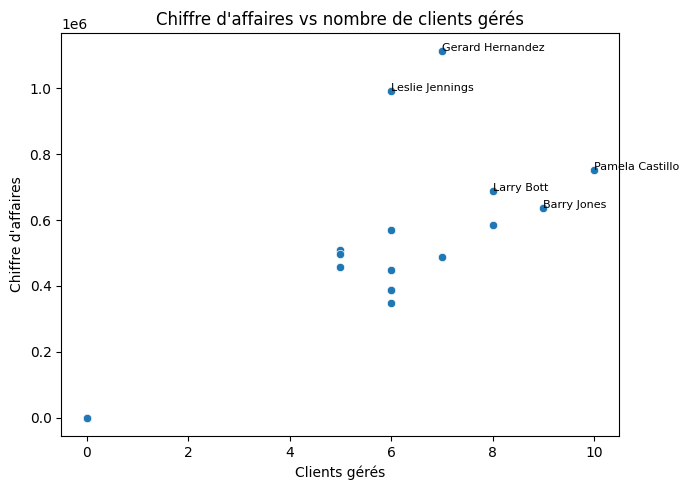

In [15]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="customers_managed", y="revenue")
plt.title("Chiffre d'affaires vs nombre de clients gérés")
plt.xlabel("Clients gérés")
plt.ylabel("Chiffre d'affaires")

# annotation légère : top 5 CA
for _, r in df.sort_values("revenue", ascending=False).head(5).iterrows():
    plt.text(r["customers_managed"], r["revenue"], r["employeeName"], fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_employee_revenue_vs_customers.png", dpi=300, bbox_inches="tight")
plt.show()

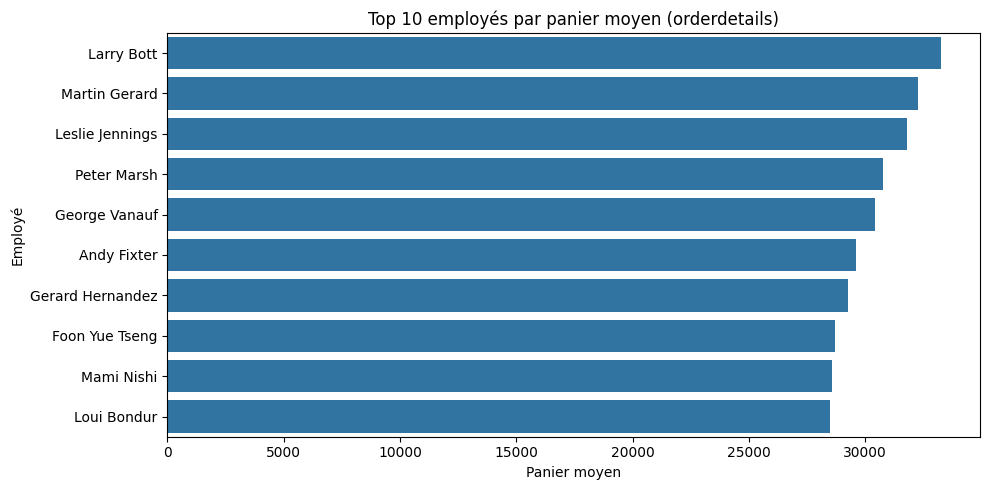

In [16]:
df_basket = df.sort_values("avg_basket", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_basket, x="avg_basket", y="employeeName")
plt.title("Top 10 employés par panier moyen (orderdetails)")
plt.xlabel("Panier moyen")
plt.ylabel("Employé")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_employee_top_avg_basket.png", dpi=300, bbox_inches="tight")
plt.show()

## Interprétation
- Un employé peut avoir **beaucoup de clients** mais un **CA plus faible** : portefeuille large mais ventes faibles (clients “petits” ou à relancer).
- Un employé avec **peu de clients** mais **fort CA** : portefeuille concentré en grands comptes.
- Le **panier moyen** aide à distinguer la qualité des ventes : commandes plus grosses vs plus nombreuses.

## Conclusion
Ces indicateurs permettent d’adapter la stratégie commerciale :
- rééquilibrage des portefeuilles,
- actions de relance ciblées,
- identification des meilleures pratiques des top performeurs.